# Using pymadng in a Jupyter notebook

`pymadng` runs MAD-NG as a subprocess and talks to it over a pair of pipes, but MAD-NG's own `print`/`io.write` output is a separate stream that is forwarded straight to Python's `stdout`/`stderr`. This notebook works as a simple check to see if this is working correctly. If you see the output of MAD-NG's `print` statements in the notebook, then everything is working as expected.

In [9]:
import os
from pathlib import Path

import matplotlib.pyplot as plt

from pymadng import MAD

os.chdir(Path.cwd())  # run from this notebook's directory so fodo.seq is found

mad = MAD()  # no stdout= argument needed: the notebook's stdout is detected automatically

MAD-NG's own `print` calls stream directly into the cell output below, live, as the sequence is loaded and twiss is computed:

In [10]:
mad.send("""
print("loading the fodo sequence...")
MADX:load("fodo.seq", "fodo.mad")
local seq in MADX
seq.beam = beam -- use default beam
print("running twiss...")
mtbl, mflw = twiss {sequence=seq, implicit=true, nslice=10, save="atbody"}
print("done")
""")

The output does not come out immediately. The python interface works asynchronously, so the MAD-NG process is running in the background while the notebook kernel is free to do other things. We only see the ouputs once we interact and MAD-NG has had a chance to flush its output buffers. Since the recv call is blocking, typically at this point you will receive this output. 

loading the fodo sequence...
running twiss...
done


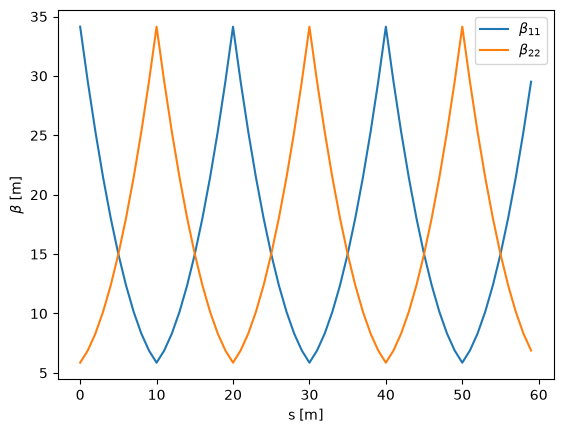

In [11]:
plt.plot(mad.mtbl.s, mad.mtbl.beta11, label=r"$\beta_{11}$")
plt.plot(mad.mtbl.s, mad.mtbl.beta22, label=r"$\beta_{22}$")
plt.xlabel("s [m]")
plt.ylabel(r"$\beta$ [m]")
plt.legend()
plt.show()

In [7]:
all_in_mad = dir(mad)
print(mad.globals())
print(all_in_mad)
mad.close()

['beam', 'beta0', 'element', 'match', 'mflw', 'mtable', 'mtbl', 'object', 'py', 'sequence', 'survey', 'track', 'twiss']
['MAD', 'MADX', 'arg', 'assert', 'beam', 'beta0', 'bit', 'close', 'collectgarbage', 'coroutine', 'create_deferred_expression', 'debug', 'dofile', 'element', 'error', 'eval', 'evaluate_in_madx_environment', 'ffi', 'gcinfo', 'getfenv', 'getmetatable', 'globals', 'help', 'history', 'io', 'ipairs', 'jit', 'load', 'load', 'loadfile', 'loadfile', 'loadstring', 'match', 'math', 'mflw', 'module', 'mtable', 'mtbl', 'newproxy', 'next', 'object', 'os', 'package', 'pairs', 'pcall', 'print', 'protected_send', 'psend', 'py', 'py_name', 'quote_strings', 'rawequal', 'rawget', 'rawlen', 'rawset', 'receive', 'recv', 'recv_and_exec', 'recv_vars', 'require', 'select', 'send', 'send_cpx_tpsa', 'send_logrange', 'send_range', 'send_tpsa', 'send_vars', 'sequence', 'setfenv', 'setmetatable', 'show', 'string', 'survey', 'table', 'tonumber', 'tostring', 'track', 'twiss', 'type', 'unpack', 'xpca